# Paso 10 · QFT en control digital (con Python)

Notebook del **Paso 10**: el efecto del muestreo (ZOH) sobre el lazo, cuánto cuesta un $T_s$ lento y qué cambia en los templates.

| Concepto matemático | Concepto de programación |
|---|---|
| $z=e^{sT_s}$, $z=e^{j\omega T_s}$ | `np.exp` con complejos, `signal.cont2discrete` |
| el ZOH ≈ retardo de $T_s/2$ | comparar fase teórica y exacta |
| frecuencia de Nyquist $\omega_N=\pi/T_s$ | rejillas de frecuencia que acaban en Nyquist |
| coste de un $T_s$ lento | tabla producida por un bucle sobre $T_s$ |
| diseño directo en discreto | reevaluar las especificaciones con $P_i(z)$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
from scipy import signal
from nbhelp import db, wrapfase, carta_nichols, poligono, AZUL, NARANJA, TINTA, GRIS, VERDE, MORADO
from qft import KS, AS, P, edge_params, spec_ok, TU, TL, delta_db, WD, WS

## 1. Qué se conserva y qué cambia

Se conserva **todo el método** (templates, bounds, loop shaping, prefiltro, verificación). Cambia dónde se evalúan las funciones: en vez de $P(j\omega)$, usamos $P(z)$ en $z=e^{j\omega T_s}$ para $\omega\in(0,\omega_N]$, con $\omega_N=\pi/T_s$.

Muestreo de la planta con un **ZOH** (retén de orden cero):

In [3]:
def Pz(K, a, Ts, w):
    """P(z) = ZOH de K/(s(s+a)), evaluada en z = e^{jωTs}."""
    n, d, _ = signal.cont2discrete(([K], [1, a, 0]), Ts, method="zoh")
    z = np.exp(1j * np.asarray(w) * Ts)
    return np.polyval(n.ravel(), z) / np.polyval(d, z)

def Gz(Ts, k, zc, pc, w):
    """Compensador k(1+s/zc)/(1+s/pc) discretizado por Tustin, evaluado en z = e^{jωTs}."""
    n, d, _ = signal.cont2discrete(([k*pc/zc, k*pc], [1, pc]), Ts, method="bilinear")
    z = np.exp(1j * np.asarray(w) * Ts)
    return np.polyval(n.ravel(), z) / np.polyval(d, z)

Ts = 0.05
n, d, _ = signal.cont2discrete(([1.0], [1, 1.0, 0]), Ts, method="zoh")
print("P0(z) con Ts = 0.05:  num =", n.ravel(), " den =", d)
print("polos de P0(z):", np.roots(d), " (z = 1 es el integrador; el otro es e^{-a Ts} =", round(np.exp(-0.05), 4), ")")

P0(z) con Ts = 0.05:  num = [0.     0.0012 0.0012]  den = [ 1.     -1.9512  0.9512]
polos de P0(z): [1.     0.9512]  (z = 1 es el integrador; el otro es e^{-a Ts} = 0.9512 )


## 2. El ZOH es un retardo de $T_s/2$

La respuesta del ZOH es $\dfrac{1-e^{-sT_s}}{s}=T_s\,e^{-sT_s/2}\,\dfrac{\sin(\omega T_s/2)}{\omega T_s/2}$: magnitud casi plana y **fase $-\omega T_s/2$**.

Ts = 0.02 : en ω = 10 pierde   5.7°;  magnitud en Nyquist: -3.91 dB
Ts = 0.05 : en ω = 10 pierde  14.3°;  magnitud en Nyquist: -3.91 dB
Ts = 0.1  : en ω = 10 pierde  28.6°;  magnitud en Nyquist: -3.91 dB


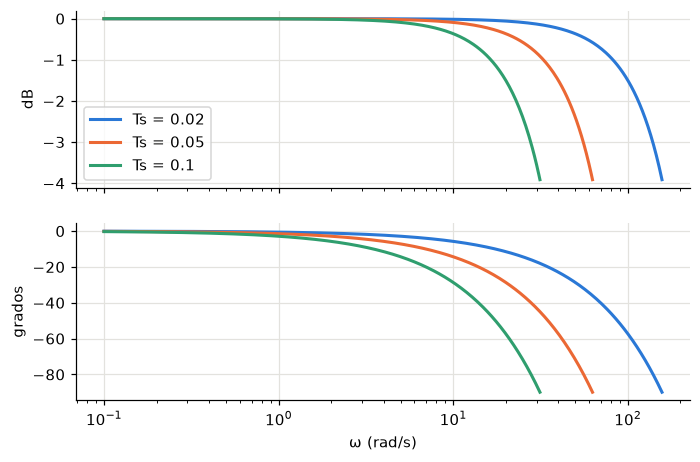

In [4]:
for Ts_ in (0.02, 0.05, 0.1):
    wN = np.pi/Ts_; w = np.logspace(-1, np.log10(wN*0.999), 400); x = w*Ts_/2
    print(f"Ts = {Ts_:<5}: en ω = 10 pierde {np.degrees(10*Ts_/2):5.1f}°;  magnitud en Nyquist: {db(np.sin(x[-1])/x[-1]):5.2f} dB")
fig, (m, p) = plt.subplots(2, 1, figsize=(7.2, 4.6), sharex=True)
for Ts_, c in ((0.02, AZUL), (0.05, NARANJA), (0.1, VERDE)):
    wN = np.pi/Ts_; w = np.logspace(-1, np.log10(wN*0.999), 400); x = w*Ts_/2
    m.semilogx(w, db(np.sin(x)/x), color=c, lw=2, label=f"Ts = {Ts_}"); p.semilogx(w, -np.degrees(x), color=c, lw=2)
m.set_ylabel("dB"); p.set_ylabel("grados"); p.set_xlabel("ω (rad/s)"); m.legend(); plt.show()

## 3. En el Nichols: la curva se desplaza a la izquierda

Comparamos $L(j\omega)$ continuo con el lazo digital (planta $K=5$, $a=1$ y el compensador del Paso 9 discretizado):

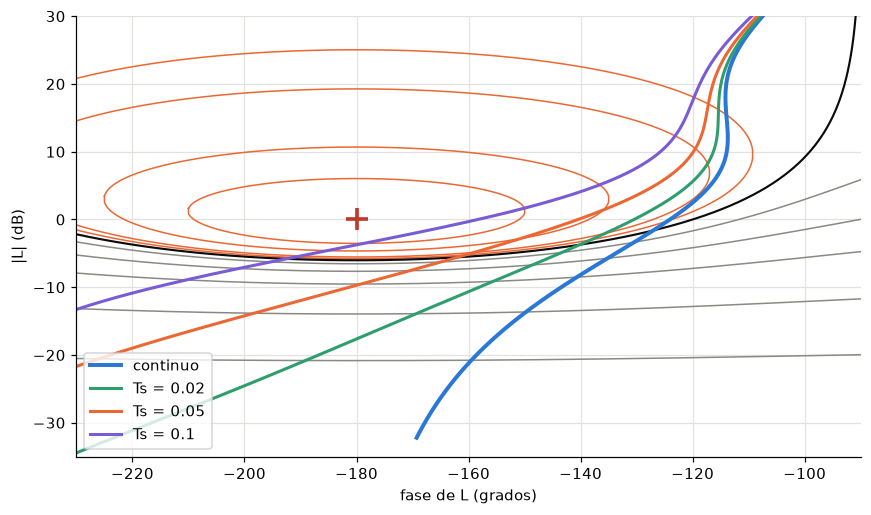

        caso   fase en ω=10      dB
    continuo        -122.2°    1.10
   Ts = 0.02        -127.9°    1.10
   Ts = 0.05        -136.7°    1.14
    Ts = 0.1        -151.9°    1.27


In [5]:
Gc = lambda w: 50*(1j*w + 2)/(1j*w + 20)
wc = np.logspace(-0.5, 2, 600); Lc = Gc(wc)*P(wc, 5, 1)
fig, ax = plt.subplots(figsize=(9.2, 5.2)); carta_nichols(ax, (-230, -90), (-35, 30))
ax.plot(wrapfase(Lc), db(Lc), color=AZUL, lw=2.6, label="continuo")
for Ts_, c in ((0.02, VERDE), (0.05, NARANJA), (0.1, MORADO)):
    w = np.logspace(-0.5, np.log10(np.pi/Ts_*0.98), 500); L = Gz(Ts_, 5, 2, 20, w)*Pz(5, 1, Ts_, w)
    ax.plot(wrapfase(L), db(L), color=c, lw=2, label=f"Ts = {Ts_}")
ax.legend(loc="lower left"); plt.show()
print(f"{'caso':>12} {'fase en ω=10':>14} {'dB':>7}")
l = Gc(10.0)*P(10.0, 5, 1); print(f"{'continuo':>12} {float(wrapfase(l)):>13.1f}° {db(l):>7.2f}")
for Ts_ in (0.02, 0.05, 0.1):
    l = Gz(Ts_, 5, 2, 20, 10.0)*Pz(5, 1, Ts_, 10.0); print(f"{'Ts = '+str(Ts_):>12} {float(wrapfase(l)):>13.1f}° {db(l):>7.2f}")

## 4. Los templates también se desplazan ($\omega=5$, $T_s=0.1$)

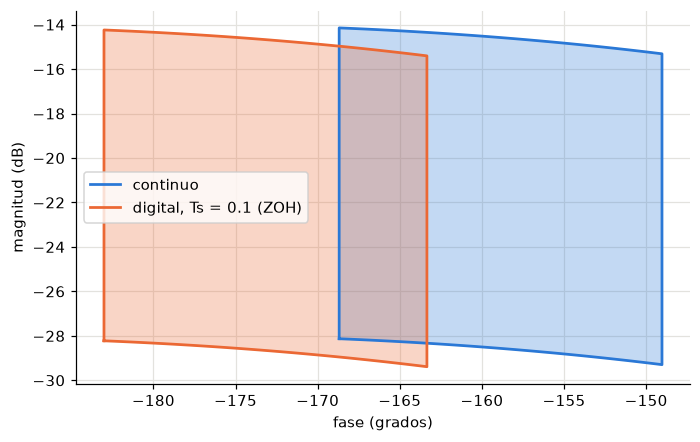

centro del template: continuo (-158.7°, -20.8 dB) -> digital (-173.0°, -20.9 dB)


In [6]:
e = edge_params(30); w0 = 5.0; Tsd = 0.1
zc = np.array([P(w0, k, a) for k, a in e]); zd = np.array([Pz(k, a, Tsd, w0) for k, a in e])
fig, ax = plt.subplots(figsize=(7.2, 4.4)); poligono(ax, zc, AZUL, "continuo"); poligono(ax, zd, NARANJA, "digital, Ts = 0.1 (ZOH)")
ax.legend(); ax.set_xlabel("fase (grados)"); ax.set_ylabel("magnitud (dB)"); plt.show()
print(f"centro del template: continuo ({wrapfase(zc).mean():.1f}°, {db(zc).mean():.1f} dB) -> digital ({wrapfase(zd).mean():.1f}°, {db(zd).mean():.1f} dB)")

## 5. Cuánto cuesta un muestreo lento

Tomamos el $G$ del Paso 9 (discretizado con Tustin) y calculamos $\max|T|$ sobre **toda** la familia y una rejilla densa de frecuencias hasta Nyquist.

In [7]:
def fam_z(Ts, z):
    cols = []
    for K in KS:
        for a in AS:
            n, d, _ = signal.cont2discrete(([K], [1, a, 0]), Ts, method="zoh"); cols.append(np.polyval(n.ravel(), z)/np.polyval(d, z))
    return np.array(cols).T                        # (nW, nPlantas)

def max_T_db(Ts, k=5, zc=2, pc=20, n=300):
    wN = np.pi/Ts; W = np.unique(np.r_[np.logspace(-1, np.log10(wN*0.995), n), 0.5, 1.0, 2.0]); z = np.exp(1j*W*Ts)
    L = Gz(Ts, k, zc, pc, W)[:, None] * fam_z(Ts, z)
    return db((np.abs(L/(1+L))).max())

print(f"{'Ts (s)':>8} {'ωs/10':>8} {'fase perdida ω=10':>19} {'max|T| (dB)':>12}  cumple ≤1.58 dB")
for Ts_ in (0.005, 0.01, 0.02, 0.05, 0.1, 0.15):
    ws = 2*np.pi/Ts_; t = max_T_db(Ts_)
    print(f"{Ts_:>8} {ws/10:>8.1f} {np.degrees(10*Ts_/2):>18.1f}° {t:>12.2f}  {'sí' if t <= 1.58 else ('al límite' if t <= 1.6 else 'no')}")

  Ts (s)    ωs/10   fase perdida ω=10  max|T| (dB)  cumple ≤1.58 dB
   0.005    125.7                1.4°         1.06  sí


    0.01     62.8                2.9°         1.21  sí
    0.02     31.4                5.7°         1.59  al límite
    0.05     12.6               14.3°         3.51  no


     0.1      6.3               28.6°        10.00  no
    0.15      4.2               43.0°        30.57  no


**Regla práctica**: $\omega_s\gtrsim30\,\omega_c$. Con $\omega_c\approx10$ rad/s, $T_s\lesssim0.02$ s. (La fila $T_s=0.15$ está casi en inestabilidad y su valor exacto depende de la rejilla de frecuencias: del orden de 30 dB.)

## 6. Dos caminos para diseñar $G(z)$

1. **Emular**: diseñar $G(s)$ y discretizar (lo que acabamos de hacer: sirve si $T_s$ es pequeño).
2. **Diseño directo**: recalcular templates y bounds con $P_i(z)$ y rediseñar el adelanto $G=k\frac{1+s/z}{1+s/p}$ (el Paso 11 detalla cómo, con el plano $z$ o el plano $w$).

Comprobamos los resultados de rediseñar:

In [8]:
for Ts_, (k, zc, pc) in ((0.02, (5, 2, 25)), (0.05, (5, 2.3, 32))):
    print(f"Ts = {Ts_:<5} adelanto rediseñado k={k}, z={zc}, p={pc}:  max|T| = {max_T_db(Ts_, k, zc, pc):.2f} dB (≤ 1.58)  frente a emular el G del paso 9: {max_T_db(Ts_):.2f} dB")

Ts = 0.02  adelanto rediseñado k=5, z=2, p=25:  max|T| = 1.04 dB (≤ 1.58)  frente a emular el G del paso 9: 1.59 dB


Ts = 0.05  adelanto rediseñado k=5, z=2.3, p=32:  max|T| = 1.56 dB (≤ 1.58)  frente a emular el G del paso 9: 3.51 dB


## 7. Ejercicio del Paso 10

Un lazo continuo tiene $\omega_c=10$ rad/s y margen de fase $56^\circ$. Se implementa con ZOH.

1. Con $T_s=0.1$ s, ¿qué retardo equivalente introduce el ZOH y cuánta fase resta en $\omega_c$? ¿Margen de fase que queda?
2. ¿Frecuencia de Nyquist? ¿Está $\omega_c$ muy cerca?
3. ¿$T_s$ máximo para perder como mucho $6^\circ$ en $\omega_c$?

**Tu turno.**

In [9]:
wc_, mf_, Ts_ = 10.0, 56.0, 0.1
# 1) retardo = Ts/2 ; fase = -wc*Ts/2 rad -> grados ; margen restante
# 2) wN = pi/Ts ; wc/wN
# 3) Ts máximo con 6° de pérdida
# escribe aquí tu código

In [10]:
retardo = Ts_/2; fase_perdida = np.degrees(wc_*retardo)
print(f"1) retardo = {retardo} s ; fase perdida = {fase_perdida:.1f}° ; margen de fase ≈ {mf_ - fase_perdida:.1f}° (aprox.)")
wN = np.pi/Ts_; print(f"2) ωN = {wN:.1f} rad/s ; ωc/ωN = {wc_/wN:.2f} (un tercio de Nyquist: pocos puntos por periodo)")
Tmax = np.radians(6)*2/wc_; print(f"3) Ts ≤ {Tmax:.4f} s (≈ 0.02 s). Con un periodo extra de retardo de cómputo: Ts ≤ {np.radians(6)/(1.5*wc_):.4f} s")

1) retardo = 0.05 s ; fase perdida = 28.6° ; margen de fase ≈ 27.4° (aprox.)
2) ωN = 31.4 rad/s ; ωc/ωN = 0.32 (un tercio de Nyquist: pocos puntos por periodo)
3) Ts ≤ 0.0209 s (≈ 0.02 s). Con un periodo extra de retardo de cómputo: Ts ≤ 0.0070 s


## 8. Resumen

- Digital: mismo método, pero con $P_i(z)$ y $\omega\in(0,\omega_N]$.
- El ZOH añade un retardo de $T_s/2$ ⇒ resta $\omega T_s/2$ rad de fase y desplaza curvas y templates a la izquierda.
- $T_s$ lento destruye el diseño continuo (tabla de la sección 5). Regla: $\omega_s\gtrsim30\,\omega_c$.
- Dos caminos: emular o diseñar directamente en discreto (Paso 11).